<a href="https://colab.research.google.com/github/aisena23/aisena23.github.io/blob/main/Hands-On-Activity-05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
laml_mutation_file = 'TCGA-LAML.somaticmutation_wxs.tsv.gz'
TCGA_LAML_MC3 = pd.read_csv(laml_mutation_file, sep='\t', compression= 'gzip')
print(f"LAML Mutation Dataset Shape: {TCGA_LAML_MC3.shape}")
TCGA_LAML_MC3.head()

LAML Mutation Dataset Shape: (3922, 12)


,sample,gene,chrom,start,end,ref,alt,Tumor_Sample_Barcode,Amino_Acid_Change,effect,callers,dna_vaf
0,TCGA-AB-2864-03B,CASZ1,chr1,10655741,10655741,C,T,TCGA-AB-2864-03B-01W-0728-08,p.G525S,missense_variant,muse;mutect2;varscan2,0.241667
1,TCGA-AB-2864-03B,SLC6A9,chr1,44002951,44002951,T,A,TCGA-AB-2864-03B-01W-0728-08,p.N282Y,missense_variant,muse;mutect2;varscan2,0.452542
2,TCGA-AB-2864-03B,ATP13A5,chr3,193310692,193310692,G,C,TCGA-AB-2864-03B-01W-0728-08,p.A824G,missense_variant,muse;mutect2;varscan2,0.354839
3,TCGA-AB-2864-03B,PCDHA13,chr5,140884461,140884461,G,A,TCGA-AB-2864-03B-01W-0728-08,p.A731=,synonymous_variant,muse;varscan2,0.489796
4,TCGA-AB-2864-03B,PPP2R2B,chr5,146590168,146590168,G,A,TCGA-AB-2864-03B-01W-0728-08,p.R371C,missense_variant,muse;mutect2;varscan2,0.443686


In [15]:
# Create a binary gene-by-sample matrix (1 if mutated, 0 otherwise)
laml_matrix = TCGA_LAML_MC3.pivot_index = TCGA_LAML_MC3.pivot_table(
   index='gene',
   columns='sample',
   values='alt',
   aggfunc=lambda x: 1,
   fill_value=0
)

# Sum across columns to get the total number of samples mutated per gene (matching cell 28)
gene_mutated_counts = laml_matrix.sum(axis=1).sort_values(ascending=False)

# Display the results
gene_mutated_counts

/tmp/ipykernel_689/4262352728.py:2: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  laml_matrix = TCGA_LAML_MC3.pivot_index = TCGA_LAML_MC3.pivot_table(


,0
gene,
NPM1,11
TTN,9
TP53,8
MUC16,8
DNMT3A,8
...,...
ABCB9,1
ABCB5,1
ABCB4,1


In [12]:
# Count how many total mutations exist per gene in the LAML dataset
gene_mutated_counts = TCGA_LAML_MC3['gene'].value_counts()

# Display the resulting counts (matching what cell 28 does)
gene_mutated_counts

,count
gene,
TTN,13
NPM1,11
TP53,11
MUC16,10
DNMT3A,9
...,...
NRP2,1
PLEKHM3,1
PRKAG3,1


In [13]:
# Look for genes most frequently mutated in LAML (matching cell 30)

top_values = gene_mutated_counts.sort_values(ascending=False).head(25)
top_values

,count
gene,
TTN,13
NPM1,11
TP53,11
MUC16,10
DNMT3A,9
RUNX1,8
BCORL1,8
ASXL1,8
IDH2,7


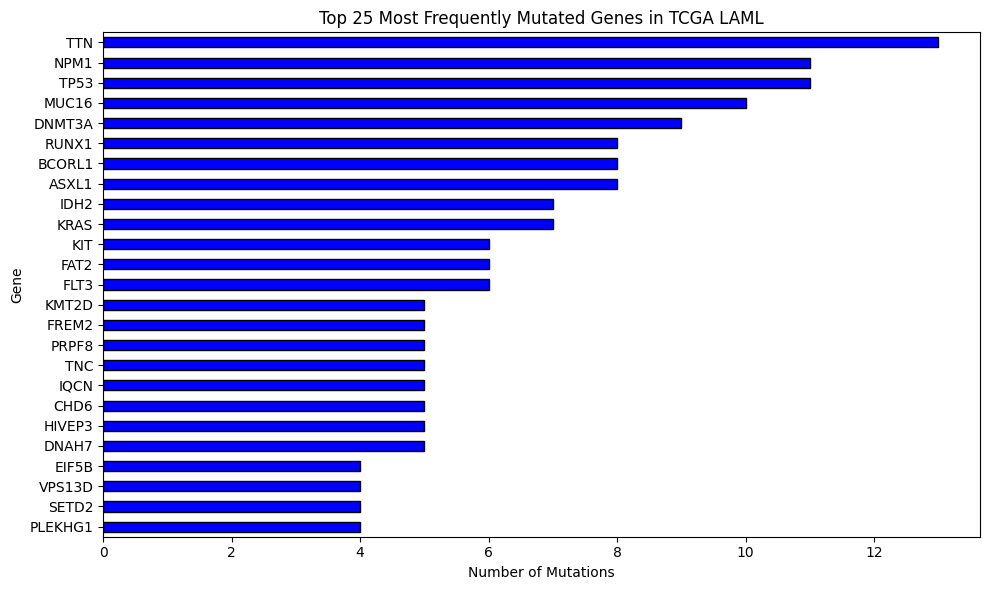

In [10]:
# Count how many times each gene appears in the mutation list
gene_types = TCGA_LAML_MC3['gene'].value_counts()

# Plot the top 25 most frequently mutated genes in LAML
top_genes = gene_types.head(25)
plt.figure(figsize=(10,6))
top_genes.plot(kind='barh', color= 'blue', edgecolor='black')
plt.xlabel("Number of Mutations")
plt.ylabel("Gene")
plt.title("Top 25 Most Frequently Mutated Genes in TCGA LAML")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [16]:
# Look into mutation types on TP53 in the LAML dataset
tp53_laml_mutations = TCGA_LAML_MC3[TCGA_LAML_MC3['gene']=='TP53']

# Print the breakdown of mutation effects (matching cell 19)
print(tp53_laml_mutations['effect'].value_counts())

# Display the filtered dataframe (matching cell 20)
tp53_laml_mutations

effect
missense_variant           8
splice_acceptor_variant    2
frameshift_variant         1
Name: count, dtype: int64


,sample,gene,chrom,start,end,ref,alt,Tumor_Sample_Barcode,Amino_Acid_Change,effect,callers,dna_vaf
617,TCGA-AB-2813-03B,TP53,chr17,7675085,7675085,C,T,TCGA-AB-2813-03B-01W-0728-08,p.C176Y,missense_variant,muse;varscan2,0.767241
1039,TCGA-AB-2904-03A,TP53,chr17,7670700,7670700,G,A,TCGA-AB-2904-03A-01W-0732-08,p.R337C,missense_variant,muse;mutect2;varscan2,0.798165
1122,TCGA-AB-2868-03B,TP53,chr17,7675237,7675237,C,T,TCGA-AB-2868-03B-01W-0728-08,p.X126_splice,splice_acceptor_variant,muse;mutect2;varscan2,0.405660
1891,TCGA-AB-2829-03B,TP53,chr17,7673782,7673782,T,C,TCGA-AB-2829-03B-01W-0728-08,p.R280G,missense_variant,muse;mutect2;varscan2,0.373418
1892,TCGA-AB-2829-03B,TP53,chr17,7674291,7674291,C,T,TCGA-AB-2829-03B-01W-0728-08,p.X225_splice,splice_acceptor_variant,muse;mutect2;varscan2,0.321782
1916,TCGA-AB-2935-03A,TP53,chr17,7674220,7674220,C,T,TCGA-AB-2935-03A-01W-0745-08,p.R248Q,missense_variant,muse;mutect2;varscan2,0.436893
1940,TCGA-AB-2935-03A,TP53,chr17,7674220,7674220,C,T,TCGA-AB-2935-03A-01W-0755-09,p.R248Q,missense_variant,muse;varscan2,0.414286
3754,TCGA-AB-2938-03A,TP53,chr17,7670685,7670685,G,-,TCGA-AB-2938-03A-01W-0732-08,p.R342Efs*3,frameshift_variant,mutect2;pindel;varscan2,0.168919
3755,TCGA-AB-2938-03A,TP53,chr17,7675076,7675076,T,C,TCGA-AB-2938-03A-01W-0732-08,p.H179R,missense_variant,muse;mutect2;varscan2,0.610759
3774,TCGA-AB-2885-03A,TP53,chr17,7674954,7674954,G,A,TCGA-AB-2885-03A-01W-0732-08,p.H193Y,missense_variant,muse;mutect2;varscan2,0.827957


In [17]:
# View the first few rows of the filtered TP53 LAML mutations
tp53_laml_mutations.head()

# View key columns for TP53 mutations in LAML
tp53_laml_mutations[['sample', 'gene', 'effect', 'Amino_Acid_Change', 'dna_vaf']].head()

,sample,gene,effect,Amino_Acid_Change,dna_vaf
617,TCGA-AB-2813-03B,TP53,missense_variant,p.C176Y,0.767241
1039,TCGA-AB-2904-03A,TP53,missense_variant,p.R337C,0.798165
1122,TCGA-AB-2868-03B,TP53,splice_acceptor_variant,p.X126_splice,0.405660
1891,TCGA-AB-2829-03B,TP53,missense_variant,p.R280G,0.373418
1892,TCGA-AB-2829-03B,TP53,splice_acceptor_variant,p.X225_splice,0.321782


In [19]:
# Filter for NPM1 mutations and check their effects (matching cell 32)
npm1_mutations = TCGA_LAML_MC3[TCGA_LAML_MC3['gene']=='NPM1']
print(npm1_mutations['effect'].value_counts())

effect
frameshift_variant    10
missense_variant       1
Name: count, dtype: int64


In [21]:
# View the head of the NPM1 mutations dataframe (matching cell 33)
npm1_mutations.head()

,sample,gene,chrom,start,end,ref,alt,Tumor_Sample_Barcode,Amino_Acid_Change,effect,callers,dna_vaf
703,TCGA-AB-2871-03A,NPM1,chr5,171410539,171410540,-,TCTG,TCGA-AB-2871-03A-01W-0732-08,p.W288Cfs*12,frameshift_variant,mutect2;pindel;varscan2,0.236111
715,TCGA-AB-2869-03A,NPM1,chr5,171410540,171410541,-,CTGC,TCGA-AB-2869-03A-01W-0761-09,p.W288Cfs*12,frameshift_variant,mutect2;pindel;varscan2,0.447368
1011,TCGA-AB-2931-03A,NPM1,chr5,171410539,171410540,-,TCTG,TCGA-AB-2931-03A-01W-0745-08,p.W288Cfs*12,frameshift_variant,mutect2;varscan2,0.300000
1084,TCGA-AB-2859-03B,NPM1,chr5,171410540,171410541,-,CTGC,TCGA-AB-2859-03B-01W-0728-08,p.W288Cfs*12,frameshift_variant,mutect2;pindel;varscan2,0.219512
1150,TCGA-AB-2925-03A,NPM1,chr5,171410539,171410540,-,TCTG,TCGA-AB-2925-03A-01W-0732-08,p.W288Cfs*12,frameshift_variant,mutect2;pindel;varscan2,0.342105


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Ensure DNA_VAF is numeric and extract SIFT scores using lowercase 'sift'
tp53_laml_mutations['SIFT_score'] = tp53_laml_mutations['SIFT'].str.extract(r"\((.*?)\)").astype(float)
tp53_laml_mutations['dna_vaf'] = pd.to_numeric(tp53_laml_mutations['dna_vaf'], errors='coerce')

# 2. Filter for missense mutations with valid SIFT scores
missense_tp53_laml = tp53_laml_mutations[
    (tp53_laml_mutations['effect'] == 'missense_variant') &
    (tp53_laml_mutations['SIFT_score'].notna())
]

# 3. Plot SIFT score distribution
plt.figure(figsize=(8, 5))
sns.histplot(missense_tp53_laml['SIFT_score'], bins=10, kde=True, color='steelblue')
plt.axvline(0.05, color='red', linestyle='--', label='Deleterious Threshold (0.05)')
plt.xlabel("SIFT Score")
plt.ylabel("Number of Missense Mutations")
plt.title("SIFT Score Distribution for TP53 Missense Mutations (LAML)")
plt.legend()
plt.tight_layout()

KeyError: 'SIFT'

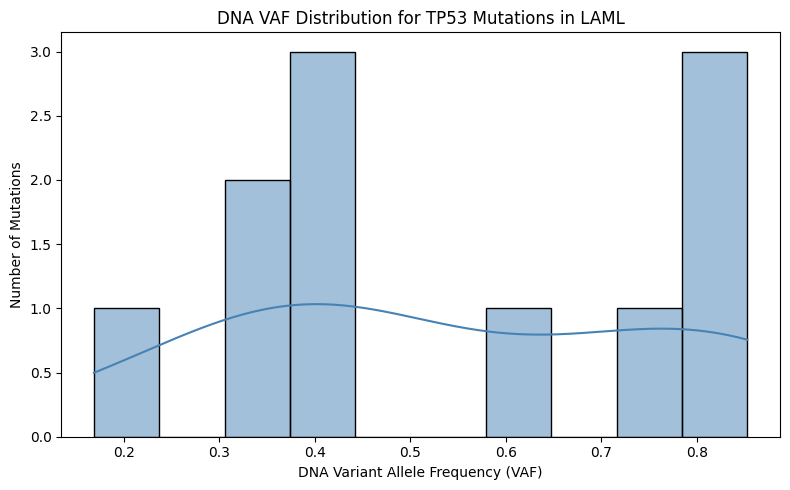

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Filter for TP53 mutations and ensure dna_vaf is numeric
tp53_laml_mutations = TCGA_LAML_MC3[TCGA_LAML_MC3['gene'] == 'TP53'].copy()
tp53_laml_mutations['dna_vaf'] = pd.to_numeric(tp53_laml_mutations['dna_vaf'], errors='coerce')

# 2. Plot the Variant Allele Frequency (VAF) distribution for TP53 in LAML
plt.figure(figsize=(8, 5))
sns.histplot(tp53_laml_mutations['dna_vaf'].dropna(), bins=10, kde=True, color='steelblue')
plt.xlabel("DNA Variant Allele Frequency (VAF)")
plt.ylabel("Number of Mutations")
plt.title("DNA VAF Distribution for TP53 Mutations in LAML")
plt.tight_layout()
plt.show()

In [33]:
import pandas as pd

# 1. Filter for TP53 mutations
tp53_laml_mutations = TCGA_LAML_MC3[TCGA_LAML_MC3['gene'] == 'TP53'].copy()

# 2. Filter for missense variants
missense_tp53_laml = tp53_laml_mutations[
    tp53_laml_mutations['effect'] == 'missense_variant'
]

# 3. View the result (matching cell 35)
missense_tp53_laml

,sample,gene,chrom,start,end,ref,alt,Tumor_Sample_Barcode,Amino_Acid_Change,effect,callers,dna_vaf
617,TCGA-AB-2813-03B,TP53,chr17,7675085,7675085,C,T,TCGA-AB-2813-03B-01W-0728-08,p.C176Y,missense_variant,muse;varscan2,0.767241
1039,TCGA-AB-2904-03A,TP53,chr17,7670700,7670700,G,A,TCGA-AB-2904-03A-01W-0732-08,p.R337C,missense_variant,muse;mutect2;varscan2,0.798165
1891,TCGA-AB-2829-03B,TP53,chr17,7673782,7673782,T,C,TCGA-AB-2829-03B-01W-0728-08,p.R280G,missense_variant,muse;mutect2;varscan2,0.373418
1916,TCGA-AB-2935-03A,TP53,chr17,7674220,7674220,C,T,TCGA-AB-2935-03A-01W-0745-08,p.R248Q,missense_variant,muse;mutect2;varscan2,0.436893
1940,TCGA-AB-2935-03A,TP53,chr17,7674220,7674220,C,T,TCGA-AB-2935-03A-01W-0755-09,p.R248Q,missense_variant,muse;varscan2,0.414286
3755,TCGA-AB-2938-03A,TP53,chr17,7675076,7675076,T,C,TCGA-AB-2938-03A-01W-0732-08,p.H179R,missense_variant,muse;mutect2;varscan2,0.610759
3774,TCGA-AB-2885-03A,TP53,chr17,7674954,7674954,G,A,TCGA-AB-2885-03A-01W-0732-08,p.H193Y,missense_variant,muse;mutect2;varscan2,0.827957
3860,TCGA-AB-2943-03A,TP53,chr17,7673803,7673803,G,A,TCGA-AB-2943-03A-01W-0745-08,p.R273C,missense_variant,muse;mutect2;varscan2,0.852941


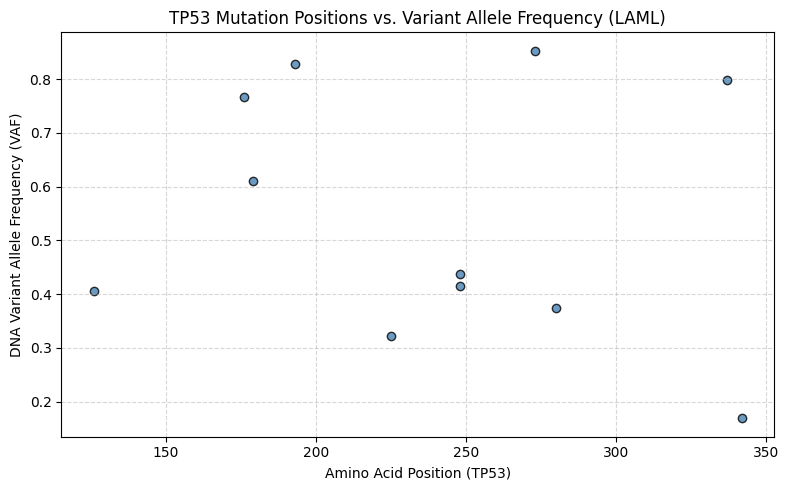

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Filter for TP53 mutations in LAML and ensure dna_vaf is numeric
tp53_laml = TCGA_LAML_MC3[TCGA_LAML_MC3['gene'] == 'TP53'].copy()
tp53_laml['dna_vaf'] = pd.to_numeric(tp53_laml['dna_vaf'], errors='coerce')

# 2. Extract the numeric amino acid position from Amino_Acid_Change (e.g., p.C176Y -> 176)
tp53_laml['AA_position'] = tp53_laml['Amino_Acid_Change'].str.extract(r'p\.\D+(\d+)\D*').astype(float)

# 3. Drop missing values and create a scatter plot of Position vs. VAF
plot_data = tp53_laml.dropna(subset=['AA_position', 'dna_vaf'])

plt.figure(figsize=(8, 5))
plt.scatter(plot_data['AA_position'], plot_data['dna_vaf'], color='steelblue', alpha=0.8, edgecolor='black')
plt.xlabel("Amino Acid Position (TP53)")
plt.ylabel("DNA Variant Allele Frequency (VAF)")
plt.title("TP53 Mutation Positions vs. Variant Allele Frequency (LAML)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [35]:
# View the LAML TP53 dataframe (matching Cell 40)
tp53_laml

,sample,gene,chrom,start,end,ref,alt,Tumor_Sample_Barcode,Amino_Acid_Change,effect,callers,dna_vaf,AA_position
617,TCGA-AB-2813-03B,TP53,chr17,7675085,7675085,C,T,TCGA-AB-2813-03B-01W-0728-08,p.C176Y,missense_variant,muse;varscan2,0.767241,176.0
1039,TCGA-AB-2904-03A,TP53,chr17,7670700,7670700,G,A,TCGA-AB-2904-03A-01W-0732-08,p.R337C,missense_variant,muse;mutect2;varscan2,0.798165,337.0
1122,TCGA-AB-2868-03B,TP53,chr17,7675237,7675237,C,T,TCGA-AB-2868-03B-01W-0728-08,p.X126_splice,splice_acceptor_variant,muse;mutect2;varscan2,0.405660,126.0
1891,TCGA-AB-2829-03B,TP53,chr17,7673782,7673782,T,C,TCGA-AB-2829-03B-01W-0728-08,p.R280G,missense_variant,muse;mutect2;varscan2,0.373418,280.0
1892,TCGA-AB-2829-03B,TP53,chr17,7674291,7674291,C,T,TCGA-AB-2829-03B-01W-0728-08,p.X225_splice,splice_acceptor_variant,muse;mutect2;varscan2,0.321782,225.0
1916,TCGA-AB-2935-03A,TP53,chr17,7674220,7674220,C,T,TCGA-AB-2935-03A-01W-0745-08,p.R248Q,missense_variant,muse;mutect2;varscan2,0.436893,248.0
1940,TCGA-AB-2935-03A,TP53,chr17,7674220,7674220,C,T,TCGA-AB-2935-03A-01W-0755-09,p.R248Q,missense_variant,muse;varscan2,0.414286,248.0
3754,TCGA-AB-2938-03A,TP53,chr17,7670685,7670685,G,-,TCGA-AB-2938-03A-01W-0732-08,p.R342Efs*3,frameshift_variant,mutect2;pindel;varscan2,0.168919,342.0
3755,TCGA-AB-2938-03A,TP53,chr17,7675076,7675076,T,C,TCGA-AB-2938-03A-01W-0732-08,p.H179R,missense_variant,muse;mutect2;varscan2,0.610759,179.0
3774,TCGA-AB-2885-03A,TP53,chr17,7674954,7674954,G,A,TCGA-AB-2885-03A-01W-0732-08,p.H193Y,missense_variant,muse;mutect2;varscan2,0.827957,193.0


In [38]:
# Cell 42 equivalent: Count mutation effects for TP53 in LAML
print("TP53 Mutation Effects in LAML:")
print(TCGA_LAML_MC3[TCGA_LAML_MC3['gene'] == 'TP53']['effect'].value_counts())

print("\n" + "="*40 + "\n")

# Cell 43 equivalent: Count mutation effects for NPM1 in LAML
print("NPM1 Mutation Effects in LAML:")
print(TCGA_LAML_MC3[TCGA_LAML_MC3['gene'] == 'NPM1']['effect'].value_counts())

TP53 Mutation Effects in LAML:
effect
missense_variant           8
splice_acceptor_variant    2
frameshift_variant         1
Name: count, dtype: int64


NPM1 Mutation Effects in LAML:
effect
frameshift_variant    10
missense_variant       1
Name: count, dtype: int64


In [39]:
# 1. Filter for TP53 missense mutations in LAML
tp53_missense = TCGA_LAML_MC3[
    (TCGA_LAML_MC3['gene'] == 'TP53') &
    (TCGA_LAML_MC3['effect'].str.contains("missense", case=False, na=False))
]

# 2. Show relevant columns: position and amino acid change (matching cell 50)
result = tp53_missense[['sample', 'chrom', 'start', 'end', 'Amino_Acid_Change', 'dna_vaf', 'effect']]

# 3. Sort by genomic start position
result = result.sort_values(by='start')

# 4. Display the result
result

,sample,chrom,start,end,Amino_Acid_Change,dna_vaf,effect
1039,TCGA-AB-2904-03A,chr17,7670700,7670700,p.R337C,0.798165,missense_variant
1891,TCGA-AB-2829-03B,chr17,7673782,7673782,p.R280G,0.373418,missense_variant
3860,TCGA-AB-2943-03A,chr17,7673803,7673803,p.R273C,0.852941,missense_variant
1916,TCGA-AB-2935-03A,chr17,7674220,7674220,p.R248Q,0.436893,missense_variant
1940,TCGA-AB-2935-03A,chr17,7674220,7674220,p.R248Q,0.414286,missense_variant
3774,TCGA-AB-2885-03A,chr17,7674954,7674954,p.H193Y,0.827957,missense_variant
3755,TCGA-AB-2938-03A,chr17,7675076,7675076,p.H179R,0.610759,missense_variant
617,TCGA-AB-2813-03B,chr17,7675085,7675085,p.C176Y,0.767241,missense_variant


In [40]:
# 1. Filter for TP53 missense mutations in LAML
tp53_missense = TCGA_LAML_MC3[
    (TCGA_LAML_MC3['gene'] == 'TP53') &
    (TCGA_LAML_MC3['effect'].str.contains("missense", case=False, na=False))
].copy()

# 2. Extract numeric amino acid position from Amino_Acid_Change (e.g., p.C176Y -> 176.0)
tp53_missense['AA_position'] = tp53_missense['Amino_Acid_Change'].str.extract(r'p\.\D+(\d+)\D*').astype(float)

# 3. Drop missing values and sort by the amino acid position
tp53_missense = tp53_missense.dropna(subset=['AA_position']).sort_values(by='AA_position')

# 4. Display the resulting columns (matching Cell 52/51 style)
print(tp53_missense[['Amino_Acid_Change', 'AA_position', 'dna_vaf']])

     Amino_Acid_Change  AA_position   dna_vaf
617            p.C176Y        176.0  0.767241
3755           p.H179R        179.0  0.610759
3774           p.H193Y        193.0  0.827957
1916           p.R248Q        248.0  0.436893
1940           p.R248Q        248.0  0.414286
3860           p.R273C        273.0  0.852941
1891           p.R280G        280.0  0.373418
1039           p.R337C        337.0  0.798165


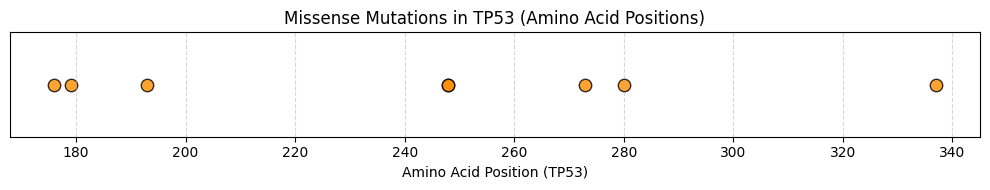

In [41]:
# Cell 52 equivalent: Generate AA position scatter plot for TP53 in LAML
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 2))
plt.scatter(
    tp53_missense['AA_position'],
    [1] * len(tp53_missense),  # y=1 for all to align horizontally
    color='darkorange',
    edgecolor='black',
    alpha=0.8,
    s=80
)
plt.xlabel("Amino Acid Position (TP53)")
plt.yticks([])  # Hide y-axis ticks
plt.title("Missense Mutations in TP53 (Amino Acid Positions)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

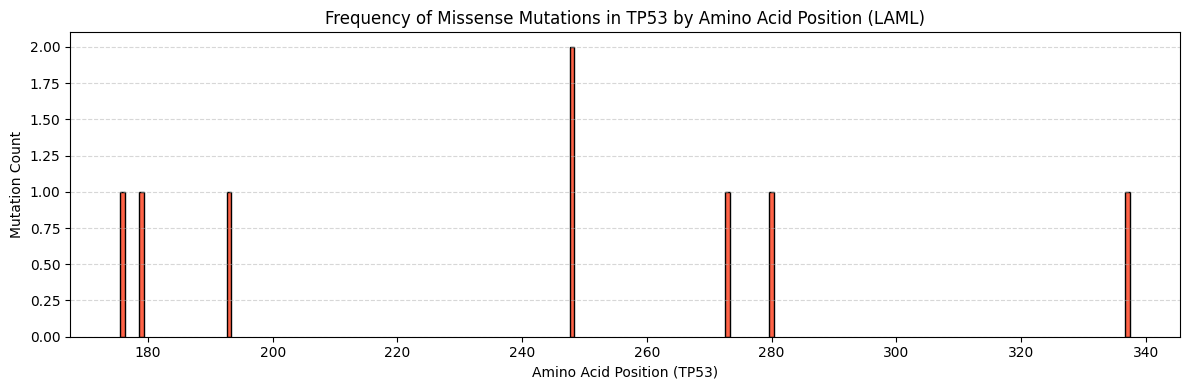

In [42]:
# Cell 54 equivalent: Frequency of Missense Mutations in TP53 by Amino Acid Position
import matplotlib.pyplot as plt

# 1. Count how many times each AA_position occurs in TP53
aa_position_counts = tp53_missense['AA_position'].value_counts().sort_index()

# 2. Plot the bar chart
plt.figure(figsize=(12, 4))
plt.bar(
    aa_position_counts.index,
    aa_position_counts.values,
    color='tomato',
    edgecolor='black'
)
plt.xlabel("Amino Acid Position (TP53)")
plt.ylabel("Mutation Count")
plt.title("Frequency of Missense Mutations in TP53 by Amino Acid Position (LAML)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Interpretation

My data set was TCGA_LAML_MC3 or a Leukemia dataset. Genes that were frequently mutated were expected and not expected. TTN, NPM1, TP53, DNMT3A etc... were all commonly mutated. While NPM1, TP53, and DNMT3A are all logically driver genes of Acute Myeloid Leukemia. Other high frequency genes are not like TTN is not a known and proven driver gene. Very large genes are sometimes at the top of charts with driver genes because of their size. Larger DNA sequences are statistically bound to DNA mutations. Additionally, raw mutations have limitations such as pooling passenger genes with driver genes due to gene size. Other limitations can be a lack of accoutability in gene length, affects of mutations on a gene, and mutation type.

# **Reflection**

# Does high mutation frequency imply functional importance?
No, a high mutation frequency does not necessarily imply functional importance. Some passenger mutations are simply along for the ride and do not directly contribute to the development of cancer and/or tumors.

# What biases might affect mutation frequency ranking?
Mutations biases such as sample size or gene length can
greatly affect mutation frequency ranking. For example,
larger genes are statistcally going to have more mutations. This can make larger genes appear to be frequently mutated driver genes, but in truth, the larger genes simply just have more to work with.

# How might you refine this analysis to better identify driver genes?
Personally, I would study the notorious and widely known driver genes. I would research their gene length, mutation types, and general behavior to better gauge what makes a driver gene so potent.